# Perturb demo A2: no forward model

Suppose all you have is **one observed sample** (with its noise) and the **retrieval as a black-box**. Without a
forward model you can't draw prior samples to fit the kernel width (`fit_kernel_width`), and you can't run the
retrieval's answers back through the model to find how far to perturb (`in_distribution_curve`), so both need to be
set by hand:

- **The magnitude**, ±3σ, which is a perturbation the noise itself could plausibly produce, so the sample should stay
  in distribution.
- **The kernel FWHM**, a few points wide, i.e. about the width of the narrowest real feature you expect to see. Here we
  use 5 points.

The Fourier CNN from demo A stands in for the black-box, but we only use its sample and `f`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "fourier")
sys.path.insert(0, str(Path("..", "src").resolve()))
import perturb as pt
from perturb import plotting
from fourier import NAMES, SIGMA, T, forward, load_black_box, sample_amplitudes

rng = np.random.default_rng(2026)
x_star = forward(sample_amplitudes(1, rng))[0] + SIGMA * rng.standard_normal(len(T))  # stand-in for your observation
f = load_black_box()                                                                    # stand-in for your retrieval

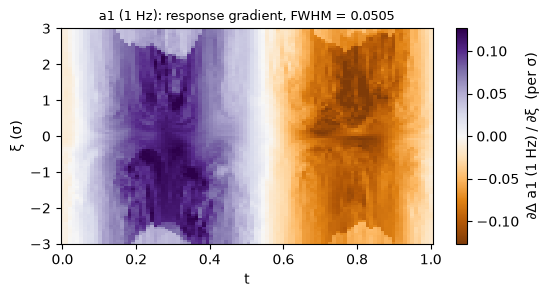

In [2]:
FWHM = 5 * np.median(np.diff(T))   # 5 points wide, in units of the feature axis
XI = pt.magnitude_grid(xi_max=3)   # -3 to +3 sigma

result = pt.Perturber(f, T, SIGMA, FWHM)(x_star, XI)
plotting.gradient_map(result, output=0, names=NAMES, xlabel="t");

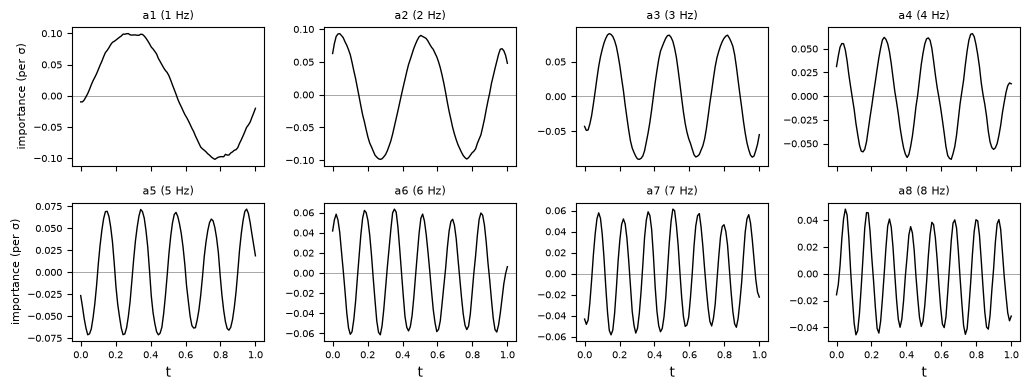

In [3]:
plotting.importance(result, names=NAMES, xlabel="t");

If you can, it's worth checking that the FWHM isn't driving the answer, by rerunning with half and double the width.
Any features that survive all three are robust.